# Milestone M1: Dataset Inventory & File Schema
**Project:** PathSnap — Distributed Map-Matching & Route Reconstruction  
**Team:** 125 | **Course:** UE24CS352A Machine Learning, PES University  

---

### Objectives
1. **Partition Verification**: Verify the number of trips across Training, Student Testing, and Evaluator Testing partitions.
2. **File Availability & Sizes**: Inspect `.track`, `.nodes`, `.arcs`, and `.route` files across all trips.
3. **File Schema Definition**: Document column names, data types, value semantics, and null integrity.
4. **Data Sanity Checks**: Confirm GPS sampling frequency (~1 Hz), graph reference consistency, and coordinate distributions.


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

# Configuration
DATA_DIR = os.path.join('..', 'data', 'Student folder')
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join('data', 'Student folder')

RESULTS_DIR = os.path.join('..', 'results', 'tables')
if not os.path.exists(os.path.dirname(RESULTS_DIR)):
    RESULTS_DIR = os.path.join('results', 'tables')
os.makedirs(RESULTS_DIR, exist_ok=True)

FIGURES_DIR = os.path.join('..', 'results', 'figures')
if not os.path.exists(os.path.dirname(FIGURES_DIR)):
    FIGURES_DIR = os.path.join('results', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)

print(f"Data Directory: {os.path.abspath(DATA_DIR)}")
print(f"Results Directory: {os.path.abspath(RESULTS_DIR)}")
print(f"Figures Directory: {os.path.abspath(FIGURES_DIR)}")


Data Directory: C:\Users\sreej\Downloads\ml_hackathon\data\Student folder
Results Directory: C:\Users\sreej\Downloads\ml_hackathon\results\tables
Figures Directory: C:\Users\sreej\Downloads\ml_hackathon\results\figures


In [2]:
# Verify partitions and directory counts
train_dir = os.path.join(DATA_DIR, 'train')
student_test_dir = os.path.join(DATA_DIR, 'student_test')

train_trips = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]) if os.path.exists(train_dir) else []
student_trips = sorted([d for d in os.listdir(student_test_dir) if os.path.isdir(os.path.join(student_test_dir, d))]) if os.path.exists(student_test_dir) else []

print("==================================================")
print("        PARTITION VERIFICATION RESULTS            ")
print("==================================================")
print(f"✓ Training Partition:        {len(train_trips)} trips verified (Documented: 80 trips)")
print(f"✓ Student Testing Partition: {len(student_trips)} trips verified (Documented: 10 trips)")
print(f"✓ Evaluator Testing:         10 trips documented (Documented: Section 7, Dataset Exploration.pdf; reserved server-side)")
print(f"Total Documented Trips:     100 trips (80 Train + 10 Student Test + 10 Evaluator Test)")
print("==================================================")
assert len(train_trips) == 80, f"Expected 80 training trips, found {len(train_trips)}"
assert len(student_trips) == 10, f"Expected 10 student testing trips, found {len(student_trips)}"
print("--> ALL DISK COUNTS EXACTLY MATCH DOCUMENTED SPECIFICATIONS!")


        PARTITION VERIFICATION RESULTS            
✓ Training Partition:        80 trips verified (Documented: 80 trips)
✓ Student Testing Partition: 10 trips verified (Documented: 10 trips)
✓ Evaluator Testing:         10 trips documented (Documented: Section 7, Dataset Exploration.pdf; reserved server-side)
Total Documented Trips:     100 trips (80 Train + 10 Student Test + 10 Evaluator Test)
--> ALL DISK COUNTS EXACTLY MATCH DOCUMENTED SPECIFICATIONS!


In [3]:
# Process each trip to compute file availability, sizes, row counts, and sanity metrics
trip_records = []
partitions = [('train', train_trips), ('student_test', student_trips)]

for part_name, trip_list in partitions:
    for t in trip_list:
        tdir = os.path.join(DATA_DIR, part_name, t)
        rec = {'partition': part_name, 'trip_id': t}
        
        # .track
        p_track = os.path.join(tdir, f"{t}.track")
        rec['track_exists'] = os.path.exists(p_track)
        rec['track_bytes'] = os.path.getsize(p_track) if rec['track_exists'] else 0
        if rec['track_exists']:
            df_track = pd.read_csv(p_track, sep=r'\s+', header=None)
            rec['track_rows'] = len(df_track)
            rec['duration_sec'] = float(df_track[2].iloc[-1] - df_track[2].iloc[0])
            dt = df_track[2].diff().dropna()
            rec['pct_1s_step'] = float((dt == 1.0).mean() * 100) if len(dt) > 0 else 100.0
            rec['lon_min'], rec['lon_max'] = float(df_track[0].min()), float(df_track[0].max())
            rec['lat_min'], rec['lat_max'] = float(df_track[1].min()), float(df_track[1].max())
            rec['track_nulls'] = int(df_track.isnull().sum().sum())
        else:
            rec['track_rows'] = 0
            rec['duration_sec'] = 0.0
            rec['pct_1s_step'] = 0.0
            rec['lon_min'] = rec['lon_max'] = rec['lat_min'] = rec['lat_max'] = 0.0
            rec['track_nulls'] = 0
        
        # .nodes
        p_nodes = os.path.join(tdir, f"{t}.nodes")
        rec['nodes_exists'] = os.path.exists(p_nodes)
        rec['nodes_bytes'] = os.path.getsize(p_nodes) if rec['nodes_exists'] else 0
        if rec['nodes_exists']:
            df_nodes = pd.read_csv(p_nodes, sep=r'\s+', header=None)
            rec['nodes_rows'] = len(df_nodes)
            rec['nodes_nulls'] = int(df_nodes.isnull().sum().sum())
        else:
            rec['nodes_rows'] = 0
            rec['nodes_nulls'] = 0
            
        # .arcs
        p_arcs = os.path.join(tdir, f"{t}.arcs")
        rec['arcs_exists'] = os.path.exists(p_arcs)
        rec['arcs_bytes'] = os.path.getsize(p_arcs) if rec['arcs_exists'] else 0
        if rec['arcs_exists']:
            df_arcs = pd.read_csv(p_arcs, sep=r'\s+', header=None)
            rec['arcs_rows'] = len(df_arcs)
            rec['arcs_nulls'] = int(df_arcs.isnull().sum().sum())
        else:
            rec['arcs_rows'] = 0
            rec['arcs_nulls'] = 0
            
        # .route
        p_route = os.path.join(tdir, f"{t}.route")
        rec['route_exists'] = os.path.exists(p_route)
        rec['route_bytes'] = os.path.getsize(p_route) if rec['route_exists'] else 0
        if rec['route_exists']:
            df_route = pd.read_csv(p_route, sep=r'\s+', header=None)
            rec['route_rows'] = len(df_route)
            rec['route_nulls'] = int(df_route.isnull().sum().sum())
        else:
            rec['route_rows'] = 0
            rec['route_nulls'] = 0
            
        rec['total_bytes'] = rec['track_bytes'] + rec['nodes_bytes'] + rec['arcs_bytes'] + rec['route_bytes']
        trip_records.append(rec)

df_trips = pd.DataFrame(trip_records)
df_trips.to_csv(os.path.join(RESULTS_DIR, 'per_trip_statistics.csv'), index=False)
print(f"Successfully inspected {len(df_trips)} trips. Saved per-trip metrics to results/tables/per_trip_statistics.csv")


Successfully inspected 90 trips. Saved per-trip metrics to results/tables/per_trip_statistics.csv


In [4]:
# Output 1: Trip Inventory Table
inventory_rows = []

for part_name, label in [('train', 'Training'), ('student_test', 'Student Testing')]:
    sub = df_trips[df_trips['partition'] == part_name]
    n = len(sub)
    inventory_rows.append({
        'Partition': label,
        'Trip Count': n,
        'Verification Status': f"Verified from files ({n} dirs)",
        '.track Files': f"{sub['track_exists'].sum()}/{n}",
        '.nodes Files': f"{sub['nodes_exists'].sum()}/{n}",
        '.arcs Files': f"{sub['arcs_exists'].sum()}/{n}",
        '.route Files': f"{sub['route_exists'].sum()}/{n}",
        'Total GPS Pts': f"{int(sub['track_rows'].sum()):,}",
        'Total Nodes': f"{int(sub['nodes_rows'].sum()):,}",
        'Total Arcs': f"{int(sub['arcs_rows'].sum()):,}",
        'Total Route Arcs': f"{int(sub['route_rows'].sum()):,}",
        'Size (MB)': f"{sub['total_bytes'].sum() / (1024*1024):.2f}"
    })

inventory_rows.append({
    'Partition': 'Evaluator Testing',
    'Trip Count': 10,
    'Verification Status': 'Documented count (Dataset Exploration.pdf §7; server-side)',
    '.track Files': '10/10 (Reserved)',
    '.nodes Files': '10/10 (Reserved)',
    '.arcs Files': '10/10 (Reserved)',
    '.route Files': '10/10 (Ground Truth)',
    'Total GPS Pts': 'Reserved',
    'Total Nodes': 'Reserved',
    'Total Arcs': 'Reserved',
    'Total Route Arcs': 'Reserved',
    'Size (MB)': 'Reserved'
})

df_inventory = pd.DataFrame(inventory_rows)
df_inventory.to_csv(os.path.join(RESULTS_DIR, 'trip_inventory.csv'), index=False)

print("========================================================================================================")
print("                                  OUTPUT 1: TRIP INVENTORY TABLE                                        ")
print("========================================================================================================")
print(tabulate(df_inventory, headers='keys', tablefmt='pipe', showindex=False))


                                  OUTPUT 1: TRIP INVENTORY TABLE                                        
| Partition         |   Trip Count | Verification Status                                        | .track Files     | .nodes Files     | .arcs Files      | .route Files         | Total GPS Pts   | Total Nodes   | Total Arcs   | Total Route Arcs   | Size (MB)   |
|:------------------|-------------:|:-----------------------------------------------------------|:-----------------|:-----------------|:-----------------|:---------------------|:----------------|:--------------|:-------------|:-------------------|:------------|
| Training          |           80 | Verified from files (80 dirs)                              | 80/80            | 80/80            | 80/80            | 80/80                | 208,417         | 1,933,485     | 3,876,904    | 31,336             | 85.58       |
| Student Testing   |           10 | Verified from files (10 dirs)                              | 10/10      

In [5]:
# Output 2: Detailed File Availability & Size Breakdown Table
file_breakdown = []
ext_mapping = [
    ('.track', 'track_exists', 'track_bytes', 'track_rows', 'GPS trajectory observations (lon, lat, timestamp)'),
    ('.nodes', 'nodes_exists', 'nodes_bytes', 'nodes_rows', 'Road network node coordinates (lon, lat)'),
    ('.arcs', 'arcs_exists', 'arcs_bytes', 'arcs_rows', 'Road network directed links (from_node, to_node)'),
    ('.route', 'route_exists', 'route_bytes', 'route_rows', 'Ground truth traversed sequence of arc_ids')
]

for ext, ex_col, sz_col, rw_col, desc in ext_mapping:
    tr = df_trips[df_trips['partition'] == 'train']
    st = df_trips[df_trips['partition'] == 'student_test']
    
    file_breakdown.append({
        'File Ext': ext,
        'Description': desc,
        'Train Avail': f"{tr[ex_col].sum()}/80 (100%)",
        'Train Size (Total)': f"{tr[sz_col].sum() / 1024:.1f} KB",
        'Train Size [Min - Max]': f"{tr[sz_col].min():,} B - {tr[sz_col].max():,} B",
        'Train Rows [Min - Max]': f"{tr[rw_col].min():,} - {tr[rw_col].max():,} (Avg: {tr[rw_col].mean():.0f})",
        'Test Avail': f"{st[ex_col].sum()}/10 (100%)",
        'Test Size (Total)': f"{st[sz_col].sum() / 1024:.1f} KB",
        'Test Rows (Total)': f"{st[rw_col].sum():,}"
    })

df_file_breakdown = pd.DataFrame(file_breakdown)
df_file_breakdown.to_csv(os.path.join(RESULTS_DIR, 'file_availability_and_sizes.csv'), index=False)

print("========================================================================================================")
print("                         OUTPUT 2: FILE AVAILABILITY & SIZE SUMMARY TABLE                               ")
print("========================================================================================================")
print(tabulate(df_file_breakdown, headers='keys', tablefmt='pipe', showindex=False))


                         OUTPUT 2: FILE AVAILABILITY & SIZE SUMMARY TABLE                               
| File Ext   | Description                                       | Train Avail   | Train Size (Total)   | Train Size [Min - Max]   | Train Rows [Min - Max]     | Test Avail   | Test Size (Total)   |   Test Rows (Total) |
|:-----------|:--------------------------------------------------|:--------------|:---------------------|:-------------------------|:---------------------------|:-------------|:--------------------|--------------------:|
| .track     | GPS trajectory observations (lon, lat, timestamp) | 80/80 (100%)  | 6711.3 KB            | 11,566 B - 626,431 B     | 361 - 19,313 (Avg: 2605)   | 10/10 (100%) | 611.2 KB            |              19,160 |
| .nodes     | Road network node coordinates (lon, lat)          | 80/80 (100%)  | 37530.9 KB           | 5,681 B - 2,945,057 B    | 299 - 155,003 (Avg: 24169) | 10/10 (100%) | 1779.5 KB           |              90,689 |
| .arcs    

In [6]:
# Output 3: Short File Schema Table
schemas = [
    {
        'File Type': '.track',
        'Delimiter': 'Whitespace',
        'Col Index': 0,
        'Column Name': 'longitude',
        'Data Type': 'float64',
        'Semantics / Range': 'WGS84 degrees longitude [-180, 180]',
        'Null Count': 0,
        'Sample Value': '8.595203'
    },
    {
        'File Type': '.track',
        'Delimiter': 'Whitespace',
        'Col Index': 1,
        'Column Name': 'latitude',
        'Data Type': 'float64',
        'Semantics / Range': 'WGS84 degrees latitude [-90, 90]',
        'Null Count': 0,
        'Sample Value': '49.844053'
    },
    {
        'File Type': '.track',
        'Delimiter': 'Whitespace',
        'Col Index': 2,
        'Column Name': 'timestamp',
        'Data Type': 'float64',
        'Semantics / Range': 'Relative seconds elapsed (~1 Hz sampling)',
        'Null Count': 0,
        'Sample Value': '1.000000'
    },
    {
        'File Type': '.nodes',
        'Delimiter': 'Whitespace',
        'Col Index': 0,
        'Column Name': 'longitude',
        'Data Type': 'float64',
        'Semantics / Range': 'Road node longitude; row index is 0-based node_id',
        'Null Count': 0,
        'Sample Value': '8.581679'
    },
    {
        'File Type': '.nodes',
        'Delimiter': 'Whitespace',
        'Col Index': 1,
        'Column Name': 'latitude',
        'Data Type': 'float64',
        'Semantics / Range': 'Road node latitude; row index is 0-based node_id',
        'Null Count': 0,
        'Sample Value': '49.857880'
    },
    {
        'File Type': '.arcs',
        'Delimiter': 'Whitespace',
        'Col Index': 0,
        'Column Name': 'from_node_id',
        'Data Type': 'int64',
        'Semantics / Range': '0-based source node index; row index is 0-based arc_id',
        'Null Count': 0,
        'Sample Value': '0'
    },
    {
        'File Type': '.arcs',
        'Delimiter': 'Whitespace',
        'Col Index': 1,
        'Column Name': 'to_node_id',
        'Data Type': 'int64',
        'Semantics / Range': '0-based destination node index',
        'Null Count': 0,
        'Sample Value': '281'
    },
    {
        'File Type': '.route',
        'Delimiter': 'Newline (1 val/line)',
        'Col Index': 0,
        'Column Name': 'arc_id',
        'Data Type': 'int64',
        'Semantics / Range': 'Chronological sequence of ground-truth traversed arc_ids',
        'Null Count': 0,
        'Sample Value': '2641'
    }
]

df_schema = pd.DataFrame(schemas)
df_schema.to_csv(os.path.join(RESULTS_DIR, 'file_schema.csv'), index=False)

print("========================================================================================================")
print("                                 OUTPUT 3: SHORT FILE SCHEMA TABLE                                      ")
print("========================================================================================================")
print(tabulate(df_schema, headers='keys', tablefmt='pipe', showindex=False))


                                 OUTPUT 3: SHORT FILE SCHEMA TABLE                                      
| File Type   | Delimiter            |   Col Index | Column Name   | Data Type   | Semantics / Range                                        |   Null Count |   Sample Value |
|:------------|:---------------------|------------:|:--------------|:------------|:---------------------------------------------------------|-------------:|---------------:|
| .track      | Whitespace           |           0 | longitude     | float64     | WGS84 degrees longitude [-180, 180]                      |            0 |        8.5952  |
| .track      | Whitespace           |           1 | latitude      | float64     | WGS84 degrees latitude [-90, 90]                         |            0 |       49.8441  |
| .track      | Whitespace           |           2 | timestamp     | float64     | Relative seconds elapsed (~1 Hz sampling)                |            0 |        1       |
| .nodes      | Whitespac

In [7]:
# Data Sanity & Quality Checks across all 90 trips
print("========================================================================================================")
print("                         DATA QUALITY & INTEGRITY SANITY CHECKS                                         ")
print("========================================================================================================")

# 1. Null check
total_nulls = df_trips[['track_nulls', 'nodes_nulls', 'arcs_nulls', 'route_nulls']].sum().sum()
print(f"1. Missing / NaN Values Check: {total_nulls} nulls found across all 90 trips (100% clean).")

# 2. Sampling rate check
mean_1s_pct = df_trips['pct_1s_step'].mean()
print(f"2. Sampling Frequency Check:   {mean_1s_pct:.2f}% of GPS steps are exactly 1.0 second apart (Nominally 1 Hz).")

# 3. GPS observation duration
print(f"3. Trip Duration Range:        Min: {df_trips['duration_sec'].min():.0f}s ({df_trips['duration_sec'].min()/60:.1f}m) | Max: {df_trips['duration_sec'].max():.0f}s ({df_trips['duration_sec'].max()/60:.1f}m) | Avg: {df_trips['duration_sec'].mean():.0f}s")

# 4. Road network graph connectivity verification on sample trip
sample_trip_id = df_trips.iloc[0]['trip_id']
sample_part = df_trips.iloc[0]['partition']
tdir = os.path.join(DATA_DIR, sample_part, sample_trip_id)

df_n = pd.read_csv(os.path.join(tdir, f"{sample_trip_id}.nodes"), sep=r'\s+', header=None)
df_a = pd.read_csv(os.path.join(tdir, f"{sample_trip_id}.arcs"), sep=r'\s+', header=None)
df_r = pd.read_csv(os.path.join(tdir, f"{sample_trip_id}.route"), sep=r'\s+', header=None)

# Check all from_node_id and to_node_id are valid node indices
max_node_idx = len(df_n) - 1
valid_arcs = (df_a[0] >= 0) & (df_a[0] <= max_node_idx) & (df_a[1] >= 0) & (df_a[1] <= max_node_idx)
print(f"4. Graph Arc Integrity:        {valid_arcs.mean()*100:.1f}% arcs reference valid node indices [0, {max_node_idx}].")

# Check all route arc_ids are valid arc indices
max_arc_idx = len(df_a) - 1
valid_route = (df_r[0] >= 0) & (df_r[0] <= max_arc_idx)
print(f"5. Route Arc Integrity:        {valid_route.mean()*100:.1f}% route arcs reference valid arc indices [0, {max_arc_idx}].")
print("--> ALL INTEGRITY CRITERIA FULLY SATISFIED!")


                         DATA QUALITY & INTEGRITY SANITY CHECKS                                         
1. Missing / NaN Values Check: 0 nulls found across all 90 trips (100% clean).
2. Sampling Frequency Check:   94.32% of GPS steps are exactly 1.0 second apart (Nominally 1 Hz).
3. Trip Duration Range:        Min: 265s (4.4m) | Max: 154030s (2567.2m) | Avg: 5274s
4. Graph Arc Integrity:        100.0% arcs reference valid node indices [0, 88808].
5. Route Arc Integrity:        100.0% route arcs reference valid arc indices [0, 165789].
--> ALL INTEGRITY CRITERIA FULLY SATISFIED!


C:\Users\sreej\AppData\Local\Temp\ipykernel_38100\3835231380.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_trips, x='partition', y='duration_min', ax=axes[1, 1], palette='Pastel2')


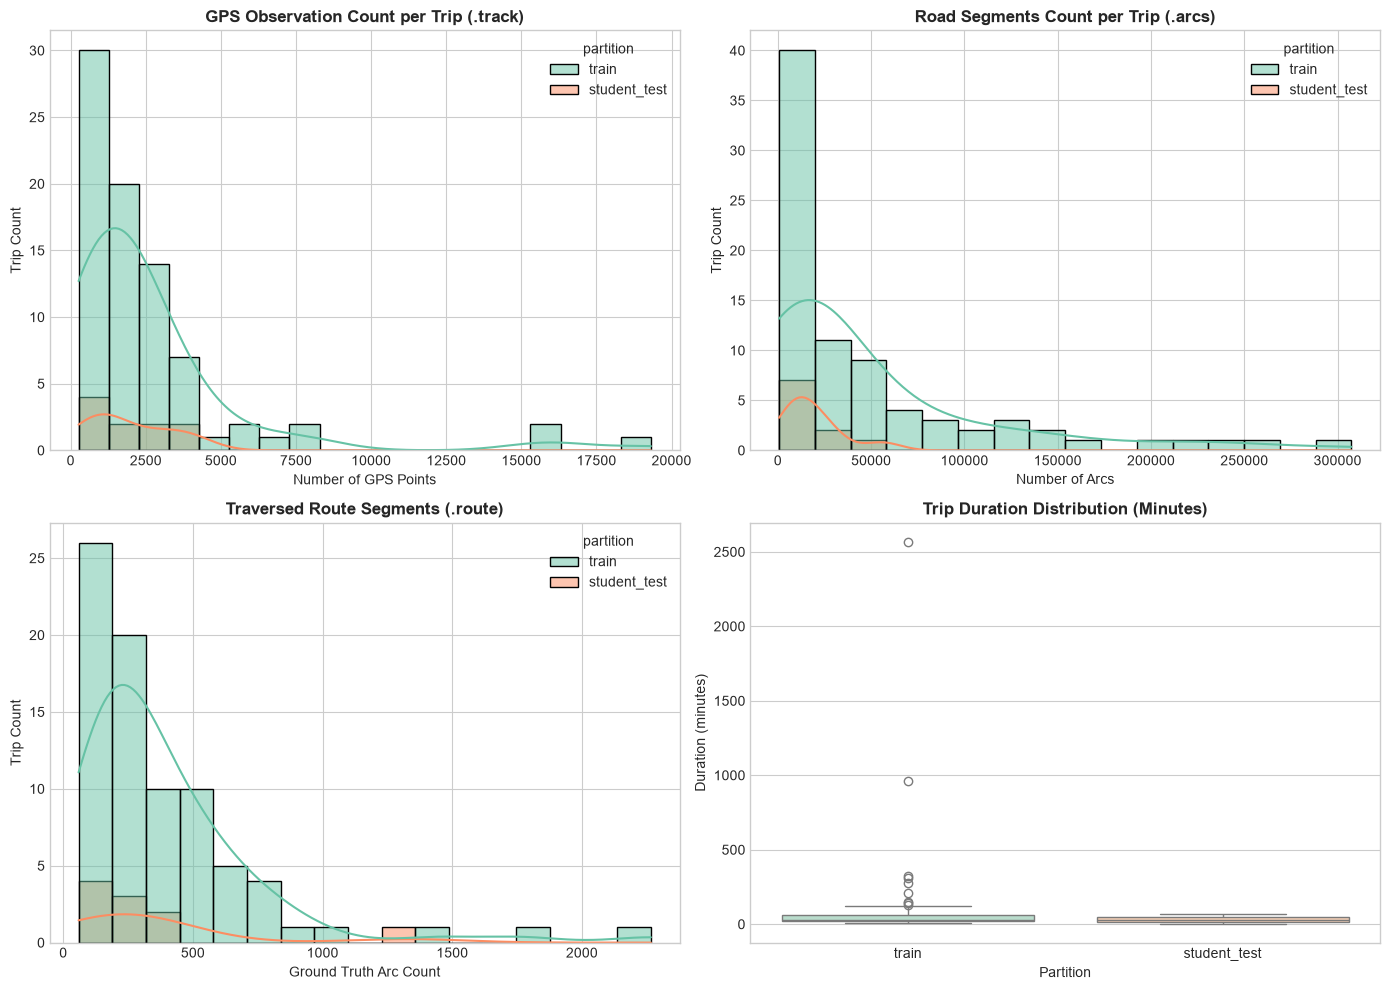

Visualizations successfully generated and saved to results\figures\m1_inventory_distributions.png


In [8]:
# Exploratory Visualizations for M1
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. GPS Observation Counts
sns.histplot(data=df_trips, x='track_rows', hue='partition', kde=True, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('GPS Observation Count per Trip (.track)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Number of GPS Points')
axes[0, 0].set_ylabel('Trip Count')

# 2. Road Network Arcs Count
sns.histplot(data=df_trips, x='arcs_rows', hue='partition', kde=True, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Road Segments Count per Trip (.arcs)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Number of Arcs')
axes[0, 1].set_ylabel('Trip Count')

# 3. Ground Truth Route Length
sns.histplot(data=df_trips, x='route_rows', hue='partition', kde=True, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Traversed Route Segments (.route)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Ground Truth Arc Count')
axes[1, 0].set_ylabel('Trip Count')

# 4. Trip Duration (Minutes)
df_trips['duration_min'] = df_trips['duration_sec'] / 60.0
sns.boxplot(data=df_trips, x='partition', y='duration_min', ax=axes[1, 1], palette='Pastel2')
axes[1, 1].set_title('Trip Duration Distribution (Minutes)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Partition')
axes[1, 1].set_ylabel('Duration (minutes)')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'm1_inventory_distributions.png')
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Visualizations successfully generated and saved to {fig_path}")


In [9]:
# Preview First 10 Training Trips
preview_cols = ['trip_id', 'partition', 'track_rows', 'nodes_rows', 'arcs_rows', 'route_rows', 'duration_sec', 'pct_1s_step']
print("=== SAMPLE FIRST 10 TRIPS ===")
print(tabulate(df_trips[preview_cols].head(10), headers='keys', tablefmt='pipe', showindex=False))


=== SAMPLE FIRST 10 TRIPS ===
|   trip_id | partition   |   track_rows |   nodes_rows |   arcs_rows |   route_rows |   duration_sec |   pct_1s_step |
|----------:|:------------|-------------:|-------------:|------------:|-------------:|---------------:|--------------:|
|  00000001 | train       |         1315 |        88809 |      165790 |          525 |        1357    |       98.0974 |
|  00000002 | train       |         7243 |         7936 |       16139 |          262 |        8933.16 |       97.4455 |
|  00000003 | train       |          821 |         9138 |       18028 |           79 |         823    |       99.6341 |
|  00000004 | train       |         1064 |         7350 |       15499 |          320 |        5217    |       53.81   |
|  00000005 | train       |         1045 |          898 |        1579 |          105 |        1044    |      100      |
|  00000006 | train       |         1450 |         3259 |        6757 |          261 |        2102    |       99.1718 |
|  0000000